![Banner](../../../../Images/Banner/07_remote_sensing/09_11_banner_rs_foundation_models.png)

# One Model for Many Sensors: DOFA, Panopticon, Copernicus-FM, CROMA and TerraMind

Most foundation models are tied to one sensor and one band layout. A newer family is built to read
any of them: Sentinel-2, Landsat, Sentinel-1 radar, WorldView, hyperspectral cubes. This notebook
uses three acquisitions of the same Iowa fields within six days in July 2025 (Sentinel-2,
Landsat 8 and Sentinel-1) to test what that flexibility is worth: can one model embed all three,
can a classifier trained on one sensor work on another, does location and date metadata help, does
combining radar with optical survive clouds, and can a generative model invent the radar image from
the optical one?

## Overview

### Why sensor-agnostic models

A conventional network has a fixed first layer: one set of weights per input band, in a fixed
order. A new satellite, a different band set or a radar image needs a new model, or a hack such as
copying weights between bands. Three ideas remove that limit:

| Idea | How it works | Models |
|---|---|---|
| Wavelength-conditioned patch embedding | a small hypernetwork turns each band's centre wavelength (and bandwidth) into that band's first-layer weights | DOFA, Copernicus-FM |
| Spectral cross-attention | every band is a token tagged with its wavelength; attention merges any number of them | Panopticon |
| One encoder per modality, fused | separate optical and SAR encoders trained so that their embeddings of the same place agree | CROMA |
| Any-to-any tokens | every modality is tokenized; the model learns to predict any modality's tokens from any other's | TerraMind |

Copernicus-FM also takes **metadata**: longitude, latitude, acquisition date and the area of the
chip, encoded like extra tokens. TerraMind can **generate** a missing modality, for example a
Sentinel-1 image from a Sentinel-2 image, which it calls "thinking in modalities".

### What flexibility does not give for free

A model that accepts Landsat bands has not necessarily learned that a Landsat pixel and a Sentinel-2
pixel of the same field should give the same embedding. Differences in resolution (30 m vs 20 m),
band width and processing shift the inputs, and the embeddings shift with them. **Cross-sensor
transfer**, training on one sensor and predicting on another, is the real test, and it is measured
below against a simple band-value baseline.

### Radar and clouds

Sentinel-1 sees through clouds; Sentinel-2 does not. CROMA's joint embedding promises a
representation that keeps working when the optical part is degraded. The test below covers half of
the test chips with synthetic cloud and compares optical-only, SAR-only and joint embeddings.

## Multi-Sensor Models with GeoLattice

| Task | GeoLattice |
|---|---|
| any band set | `fm.load_model("dofa-base", bands=...)` or `wavelengths=[...]` in nm |
| SAR channels for Panopticon | band names `vv`, `vh` (mapped to its SAR channel ids) |
| location and date | `enc.embed_raster(da, metadata=True)` (Copernicus-FM) |
| optical, SAR or both | `fm.load_model("croma-base", modality="optical" / "sar" / "both")` |
| several modalities at once | `fm.load_model("terramind-v1-base", modalities=["S2L2A", "S1GRD"])` |
| inputs per contract | `fm.prepare(name, da, modality=...)` |

### Learning objectives

1. Embed Sentinel-2, Landsat 8 and Sentinel-1 of the same fields with wavelength-aware models.
2. Measure cross-sensor transfer from Sentinel-2 to Landsat against a band-value baseline.
3. Test whether location and date metadata change Copernicus-FM embeddings.
4. Compare CROMA's optical, SAR and joint embeddings, with and without simulated clouds.
5. Run TerraMind on two modalities and generate Sentinel-1 from Sentinel-2.
6. Embed an eight-band WorldView-2 image with explicit wavelengths.

### Data

| Dataset | Date | Content |
|---|---|---|
| Corn Belt Sentinel-2 | 14 July 2025 | 10 bands, 20 m |
| Corn Belt Landsat 8 OLI | 15 July 2025 | 7 reflective bands, 30 m, resampled to the 20 m grid |
| Corn Belt Sentinel-1 GRD | 20 July 2025 | VV and VH backscatter in dB, 20 m |
| Cropland Data Layer | 2025 | six groups on the 20 m grid |
| WorldView-2, Bangladesh | | 8 bands (coastal to NIR2), 1.6 m |

### Contents

- Setup
- Three sensors, one week, one landscape
- One model, three sensors
- From Sentinel-2 to Landsat: cross-sensor transfer
- Copernicus-FM: does metadata matter?
- CROMA: optical, radar and both under clouds
- TerraMind: two modalities in, one generated
- An eight-band WorldView-2 image
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-foundation]`, which no GeoLattice option installs: `pip install "geolattice[rsense-foundation]"`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

CUBE = IC / "Corn_belt" / "cache_20m"  # Corn Belt cubes on the 20 m grid
LANDSAT = IC / "Corn_belt" / "Landsat_9" / "2025_07_LC08_L2SP_027030_20250715_02_T1"  # Landsat 8, 15 July 2025
WV2 = IC / "WorldView2_BD" / "Images" / "multi.tif"  # WorldView-2, 8 bands
CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # CDL groups 0 to 5
CHIP = 32  # chip size in 20 m pixels (640 m)

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


## Three sensors, one week, one landscape

The Sentinel-2 and Sentinel-1 scenes come from the Corn Belt cubes. The Landsat 8 Collection 2
Level-2 bands are stored as digital numbers; reflectance is `DN x 0.0000275 - 0.2`. They are
resampled to the Sentinel-2 grid with `rio.reproject_match`. Landsat's NIR band (OLI band 5,
865 nm) corresponds to Sentinel-2 band 8A, so it is named `nir08`.

Sentinel-2  {'band': 10, 'y': 1456, 'x': 1516} | bands: [np.str_('blue'), np.str_('green'), np.str_('red'), np.str_('rededge1'), np.str_('rededge2'), np.str_('rededge3'), np.str_('nir'), np.str_('nir08'), np.str_('swir16'), np.str_('swir22')] | missing 0.0%
Landsat 8   {'band': 7, 'y': 1456, 'x': 1516} | bands: ['coastal', 'blue', 'green', 'red', 'nir08', 'swir16', 'swir22'] | missing 0.0%
Sentinel-1  {'band': 2, 'y': 1456, 'x': 1516} | bands: [np.str_('vv'), np.str_('vh')] | missing 0.0%


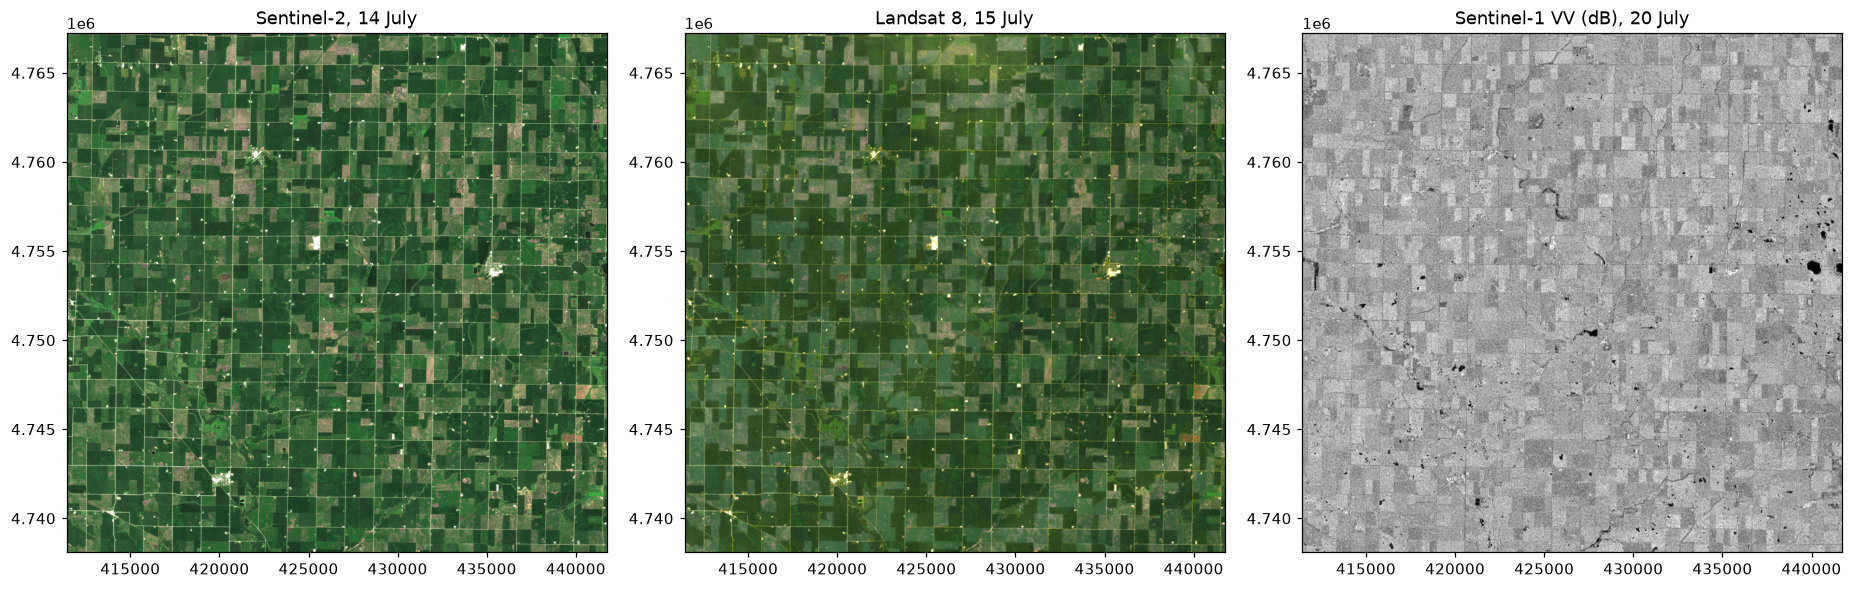

In [2]:
s2 = xr.open_dataarray(CUBE / "s2_20m.nc").sel(time="2025-07-14").drop_vars("time").load().rio.write_crs("EPSG:32615")  # Sentinel-2
s1 = xr.open_dataarray(CUBE / "s1_20m.nc").sel(time="2025-07-20").drop_vars("time").load().rio.write_crs("EPSG:32615")  # Sentinel-1 dB
LS_BANDS = {"coastal": "coastal", "blue": "blue", "green": "green", "red": "red", "nir": "nir08",
            "swir16": "swir16", "swir22": "swir22"}  # Landsat file -> GeoLattice band name
ls = xr.concat([rioxarray.open_rasterio(LANDSAT / f"{f}.tif", masked=True).squeeze("band", drop=True)
                for f in LS_BANDS], dim=pd.Index(list(LS_BANDS.values()), name="band"))  # 7 bands, 30 m
ls = (ls * 0.0000275 - 0.2).rio.write_crs(ls.rio.crs)  # Collection 2 scale and offset to reflectance
ls = ls.rio.reproject_match(s2.isel(band=0), resampling=1).assign_coords(x=s2.x, y=s2.y)  # bilinear onto the 20 m grid
cdl = xr.open_dataset(CUBE / "labels_20m.nc")["cdl"].sel(year=2025).load()  # CDL 2025
for n, da in {"Sentinel-2": s2, "Landsat 8": ls, "Sentinel-1": s1}.items():  # check each sensor
    print(f"{n:11s}", dict(da.sizes), "| bands:", list(da.band.values), f"| missing {float(da.isnull().any('band').mean()):.1%}")  # summary

fig, ax = plt.subplots(1, 3, figsize=(17, 5.5))  # three sensors
ext = [float(s2.x.min()), float(s2.x.max()), float(s2.y.min()), float(s2.y.max())]  # extent
for a, (t, da) in zip(ax[:2], {"Sentinel-2, 14 July": s2, "Landsat 8, 15 July": ls}.items()):  # optical
    a.imshow(np.clip(np.nan_to_num(da.sel(band=["red", "green", "blue"]).transpose("y", "x", "band").values) / 0.15, 0, 1), extent=ext)  # true colour
    a.set_title(t)  # title
ax[2].imshow(s1.sel(band="vv"), cmap="gray", vmin=-20, vmax=-2, extent=ext); ax[2].set_title("Sentinel-1 VV (dB), 20 July")  # radar
plt.tight_layout(); plt.show()  # draw

The two optical images agree in pattern; Landsat looks softer because it was resampled from 30 m.
In the radar image corn fields (tall stalks, strong volume scattering) are brighter than soybeans.

Chips and labels follow notebook 09_11_03: 32 pixel (640 m) chips, the majority CDL class when it
covers at least 60 % of the chip, corn and soybeans only, and 5.8 km blocks for spatial folds. The
western half of the scene trains and the eastern half tests when a single split is needed.

In [3]:
ny, nx = -(-cdl.shape[0] // CHIP), -(-cdl.shape[1] // CHIP)  # chip grid
pad = np.full((ny * CHIP, nx * CHIP), -1, cdl.dtype); pad[:cdl.shape[0], :cdl.shape[1]] = cdl.values  # padded CDL
blk = pad.reshape(ny, CHIP, nx, CHIP).transpose(0, 2, 1, 3).reshape(ny * nx, -1)  # pixels per chip
counts = np.stack([(blk == k).sum(1) for k in (0, 1)], 1)  # corn and soybean pixels
major, purity = counts.argmax(1), counts.max(1) / blk.shape[1]  # majority and share
gy, gx = np.divmod(np.arange(ny * nx), nx)  # chip row and column
group = (gy // 9) * 10 + gx // 9  # spatial blocks
ok = purity >= 0.6  # pure corn or soybean chips
west, east = ok & (gx < nx // 2), ok & (gx >= nx // 2)  # single split for transfer tests
y = major  # labels
print(ok.sum(), "chips |", west.sum(), "west |", east.sum(), "east")  # sizes

1449 chips | 736 west | 713 east


## One model, three sensors

DOFA takes any optical band set through its wavelengths. Panopticon takes optical bands by
wavelength and radar channels by special negative ids, so it alone reads all three sensors here.
Each model embeds each sensor with its default per-band standardization; the probe is the spatial
5-fold linear probe of the previous notebooks, and the baseline is the chip mean of each band.

In [4]:
SENSORS = {"Sentinel-2": s2, "Landsat 8": ls, "Sentinel-1": s1}  # the three inputs
emb, rows = {}, []  # embeddings and probe results
flat = lambda m: m.values.reshape(m.sizes["embedding"], -1).T  # (chips, D)
for model in ["dofa-base", "panopticon"]:  # wavelength-aware models
    enc = fm.load_model(model, device=DEVICE)  # load once
    for sname, da in SENSORS.items():  # every sensor
        if model == "dofa-base" and sname == "Sentinel-1":  # DOFA is used for optical bands here
            continue  # skip radar
        enc.bands, enc.wavelengths = None, None  # let embed_raster read this sensor's bands
        emb[(model, sname)] = flat(enc.embed_raster(da, chip_size=CHIP, norm="model", batch_size=64))  # (chips, D)
        rows.append({"input": model, "sensor": sname,
                     "F1": fm.linear_probe(emb[(model, sname)][ok], y[ok], groups=group[ok])["mean"]["f1_macro"]})  # probe
    del enc; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
for sname, da in SENSORS.items():  # band-mean baseline per sensor
    bm = np.nan_to_num(fm.chip_raster(da, chip_size=CHIP)[0].mean((2, 3)))  # mean of every band per chip
    emb[("band means", sname)] = bm  # keep it for transfer
    rows.append({"input": "band means", "sensor": sname, "F1": fm.linear_probe(bm[ok], y[ok], groups=group[ok])["mean"]["f1_macro"]})  # probe
pd.DataFrame(rows).pivot(index="input", columns="sensor", values="F1")[list(SENSORS)].round(3)  # inputs x sensors

sensor,Sentinel-2,Landsat 8,Sentinel-1
input,,,
band means,0.994,0.978,0.898
dofa-base,0.996,0.992,NaN
panopticon,0.998,0.993,0.923


In mid-July every optical input separates corn and soybeans almost perfectly, Sentinel-2 or
Landsat, band means or embeddings: the crops differ strongly in the near and shortwave infrared at
this time of year. The radar is the harder input. Band means of VV and VH reach about 0.90, and
Panopticon's radar embeddings about 0.92, a modest gain, while DOFA is not used on radar here. The
interesting question is not whether a model can read each sensor, but whether what it learned from
one sensor carries over to another.

## From Sentinel-2 to Landsat: cross-sensor transfer

A logistic regression is trained on Sentinel-2 chips in the west and applied to the eastern chips
twice: once on Sentinel-2 (same sensor) and once on Landsat 8 (other sensor). For the band-mean
baseline only the six bands both sensors share are used.

In [5]:
from sklearn.linear_model import LogisticRegression  # the transferred classifier
from sklearn.metrics import f1_score  # scores
from sklearn.pipeline import make_pipeline  # scaling + model
from sklearn.preprocessing import StandardScaler  # feature scaling

common = [list(s2.band.values).index(b) for b in ["blue", "green", "red", "nir08", "swir16", "swir22"]]  # shared S2 bands
common_ls = [list(ls.band.values).index(b) for b in ["blue", "green", "red", "nir08", "swir16", "swir22"]]  # same in Landsat
pairs = {"band means (6 shared bands)": (emb[("band means", "Sentinel-2")][:, common], emb[("band means", "Landsat 8")][:, common_ls]),
         "dofa-base": (emb[("dofa-base", "Sentinel-2")], emb[("dofa-base", "Landsat 8")]),
         "panopticon": (emb[("panopticon", "Sentinel-2")], emb[("panopticon", "Landsat 8")])}  # S2 and Landsat features
rows = []  # transfer results
for n, (A, B) in pairs.items():  # every input
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(A[west], y[west])  # train on S2, west
    same = f1_score(y[east], clf.predict(A[east]), average="macro")  # S2 east
    other = f1_score(y[east], clf.predict(B[east]), average="macro")  # Landsat east
    cos = np.median((A[ok] * B[ok]).sum(1) / (np.linalg.norm(A[ok], axis=1) * np.linalg.norm(B[ok], axis=1) + 1e-12))  # S2 vs Landsat agreement
    rows.append({"input": n, "F1 Sentinel-2 -> Sentinel-2": same, "F1 Sentinel-2 -> Landsat": other,
                 "drop": same - other, "median cosine S2 vs Landsat": cos})  # record
pd.DataFrame(rows).set_index("input").round(3)  # transfer table

,F1 Sentinel-2 -> Sentinel-2,F1 Sentinel-2 -> Landsat,drop,median cosine S2 vs Landsat
input,,,,
band means (6 shared bands),0.968,0.731,0.237,0.999
dofa-base,0.992,0.442,0.550,0.942
panopticon,0.988,0.943,0.045,0.734


The three inputs behave very differently. A classifier trained on Panopticon's Sentinel-2
embeddings still reaches about 0.94 on the Landsat embeddings of the same fields. The same classifier
on DOFA embeddings collapses to about 0.44, below the band-mean baseline (about 0.73). The cosine column
shows why that is surprising: DOFA's Sentinel-2 and Landsat embeddings of a chip are, on the whole, more
alike (0.94) than Panopticon's (0.73). What matters is not the overall similarity but whether the
small direction that separates corn from soybeans is preserved across sensors. In DOFA a shift caused
by the different sensor (30 m resampled, broader bands) moves the embeddings across the decision
boundary; in Panopticon it does not. Accepting a sensor's bands is not the same as transferring between
sensors, and cross-sensor transfer must always be measured.

## Copernicus-FM: does metadata matter?

Copernicus-FM accepts, for every chip, its longitude and latitude, acquisition date and area. With
`metadata=True`, `embed_raster` computes them from the raster coordinates (`fm.chip_metadata`) and
passes them to the model; without it, they are unknown (NaN) and the model ignores them.

In [6]:
cfm = fm.load_model("copernicus-fm", device=DEVICE)  # Copernicus-FM ViT-Base
s2t = s2.assign_attrs(time="2025-07-14")  # acquisition date for the metadata
with_meta = flat(cfm.embed_raster(s2t, chip_size=CHIP, norm="model", metadata=True, batch_size=64))  # lon, lat, date, area
no_meta = flat(cfm.embed_raster(s2t, chip_size=CHIP, norm="model", batch_size=64))  # metadata unknown
del cfm; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
meta = fm.chip_metadata(fm.chip_raster(s2, chip_size=CHIP)[1], fm.chip_raster(s2, chip_size=CHIP)[2], s2.rio.crs,
                        time="2025-07-14", chip_size=CHIP, resolution=20)  # what the model received
print(meta.head(3).round(4))  # first chips
cos = (with_meta * no_meta).sum(1) / (np.linalg.norm(with_meta, axis=1) * np.linalg.norm(no_meta, axis=1))  # agreement
pd.DataFrame({"F1": {"with metadata": fm.linear_probe(with_meta[ok], y[ok], groups=group[ok])["mean"]["f1_macro"],
                     "without metadata": fm.linear_probe(no_meta[ok], y[ok], groups=group[ok])["mean"]["f1_macro"]},
              "median cosine between the two": {"with metadata": float(np.median(cos)), "without metadata": float(np.median(cos))}}).round(3)  # comparison

       lon      lat     days    year    doy  area_km2
0 -94.0837  43.0497  20283.0  2025.0  195.0    0.4096
1 -94.0758  43.0497  20283.0  2025.0  195.0    0.4096
2 -94.0680  43.0498  20283.0  2025.0  195.0    0.4096


,F1,median cosine between the two
with metadata,1.0,0.997
without metadata,1.0,0.997


The metadata barely changes the embeddings (median cosine about 0.997 between the two versions), and
the July corn and soybean task is solved perfectly either way. Location and date encodings matter for
tasks that depend on them, such as crop calendars across regions or seasons, and for models trained to
use them; on one scene and one date they add nothing measurable.

## CROMA: optical, radar and both under clouds

CROMA has separate optical (12 Sentinel-2 bands) and radar (VV, VH) encoders trained to agree, plus
a joint embedding. Its input chips are 120 pixels, so the 32 pixel chips are resized to 120. Three
embeddings are computed: optical only, SAR only and joint.

To simulate clouds, the optical input of a random half of the eastern chips is replaced by a bright,
flat patch: three standard deviations above the scene mean in every standardized band, which is how a
thick cloud looks after the same normalization. A classifier trained on clean western chips is then
scored on the eastern chips, with and without the clouds.

In [7]:
opt = fm.prepare("croma-base", s2)  # 12 optical bands, standardized over the scene
sar = fm.prepare("croma-base", s1, modality="sar")  # VV, VH, standardized
resize = lambda c: torch.nn.functional.interpolate(torch.as_tensor(c), size=120, mode="bilinear").numpy()  # 32 -> 120 px
Co = resize(fm.chip_raster(opt, chip_size=CHIP)[0])  # optical chips
Cs = resize(fm.chip_raster(sar, chip_size=CHIP)[0])  # radar chips
rng = np.random.default_rng(SEED)  # random generator
e_idx = np.flatnonzero(east)  # eastern labelled chips
cloudy = np.zeros(len(Co), bool); cloudy[rng.choice(e_idx, len(e_idx) // 2, replace=False)] = True  # half get clouds
Cc = Co.copy(); Cc[cloudy] = 3.0  # bright flat cloud in standardized units
print(f"{cloudy.sum()} of {east.sum()} eastern chips clouded")  # how many

croma = {}  # embeddings per variant
for mode in ["optical", "sar", "both"]:  # three CROMA heads
    enc = fm.load_model("croma-base", device=DEVICE, modality=mode)  # CROMA with that modality
    if mode == "sar":  # radar only: clouds do not matter
        croma[("sar", "clear")] = croma[("sar", "clouds")] = enc.embed(Cs, batch_size=64)  # radar embeddings
    else:  # optical or joint
        kw = {"x_sar": Cs} if mode == "both" else {}  # joint mode also takes the radar chips
        croma[(mode, "clear")] = enc.embed(Co, batch_size=64, **kw)  # clean optical input
        croma[(mode, "clouds")] = enc.embed(Cc, batch_size=64, **kw)  # clouded optical input
    del enc; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory

rows = []  # cloud test
for mode in ["optical", "sar", "both"]:  # every embedding
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(croma[(mode, "clear")][west], y[west])  # train clean, west
    for cond in ["clear", "clouds"]:  # test condition
        pred = clf.predict(croma[(mode, cond)][east])  # predict east
        pc = clf.predict(croma[(mode, cond)][cloudy])  # predictions on the clouded chips
        rows.append({"embedding": mode, "test": cond, "F1 all east": f1_score(y[east], pred, average="macro"),
                     "F1 clouded chips": f1_score(y[cloudy], pc, average="macro"),
                     "clouded chips called corn": (pc == 0).mean()})  # scores and what the classifier says
pd.DataFrame(rows).pivot(index="embedding", columns="test").round(3)  # embedding x condition

356 of 713 eastern chips clouded


F1 all east        F1 clouded chips         \
test            clear clouds            clear clouds   
embedding                                              
both            0.999  0.687            0.997  0.273   
optical         0.999  0.687            0.997  0.273   
sar             0.909  0.909            0.905  0.905   

          clouded chips called corn         
test                          clear clouds  
embedding                                   
both                          0.621  0.000  
optical                       0.621  0.000  
sar                           0.601  0.601

On clear chips all three embeddings classify well, radar alone at about 0.91. Under clouds the
optical and the joint embeddings fail in the same way: the classifier calls almost every clouded chip
the same crop, and macro F1 on those chips falls to about 0.27. The radar-only embedding is unaffected.
CROMA's joint embedding does not fall back on radar by itself when the optical half is corrupted. In
practice clouds must be masked, and a radar-only embedding (or a classifier trained with cloudy
examples) used where the optical input is unreliable.

## TerraMind: two modalities in, one generated

TerraMind's encoder takes several modalities at once as a dictionary. Each is prepared with its own
statistics (`fm.prepare(..., modality="S1GRD")` for radar). Its embeddings of Sentinel-2 alone,
Sentinel-1 alone and both together are probed like the others; TerraMind reads 224 pixel chips, so
the 32 pixel chips are resized.

In [8]:
resize224 = lambda c: torch.nn.functional.interpolate(torch.as_tensor(c), size=224, mode="bilinear").numpy()  # 32 -> 224 px
X2 = resize224(fm.chip_raster(fm.prepare("terramind-v1-base", s2), chip_size=CHIP)[0])  # S2L2A chips (12 bands)
X1 = resize224(fm.chip_raster(fm.prepare("terramind-v1-base", s1, modality="S1GRD"), chip_size=CHIP)[0])  # S1GRD chips


def tm_embed(enc, inputs, batch=32):  # embed dicts of modalities in batches
    out = []  # embeddings
    for i in range(0, len(next(iter(inputs.values()))), batch):  # batches
        d = {k: torch.as_tensor(v[i:i + batch]) for k, v in inputs.items()}  # one batch per modality
        out.append(enc.encode(d).float().cpu().numpy())  # pooled tokens
    return np.concatenate(out)  # (chips, 768)


tm = {}  # embeddings
for mods, inputs in {"S2L2A": {"S2L2A": X2}, "S1GRD": {"S1GRD": X1}, "S2L2A + S1GRD": {"S2L2A": X2, "S1GRD": X1}}.items():  # variants
    enc = fm.load_model("terramind-v1-base", device=DEVICE, modalities=list(inputs))  # encoder for these modalities
    tm[mods] = tm_embed(enc, inputs)  # embeddings
    del enc; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
pd.DataFrame({"F1": {k: fm.linear_probe(v[ok], y[ok], groups=group[ok])["mean"]["f1_macro"] for k, v in tm.items()}}).round(3)  # probes

,F1
S2L2A,1.000
S1GRD,0.916
S2L2A + S1GRD,0.999


TerraMind's encoder classifies the July crops perfectly from Sentinel-2 and reaches about 0.92 from
Sentinel-1 alone, close to Panopticon's radar embeddings. Adding radar to optical does not improve an
already perfect optical score; the value of the radar input lies in scenes where the optical input is
missing or cloudy.

The generative TerraMind model turns a Sentinel-2 chip into a Sentinel-1 chip by iterative
denoising of radar tokens. It is built from TerraTorch's model registry. Inputs are standardized
with `fm.prepare` and the output is converted back to dB with TerraMind's radar statistics.

mean dB  generated: [ -8.87 -15.35] | real: [ -8.65 -14.78]
correlation VV, pixels: 0.19 | 16 x 16 px blocks (320 m): 0.527


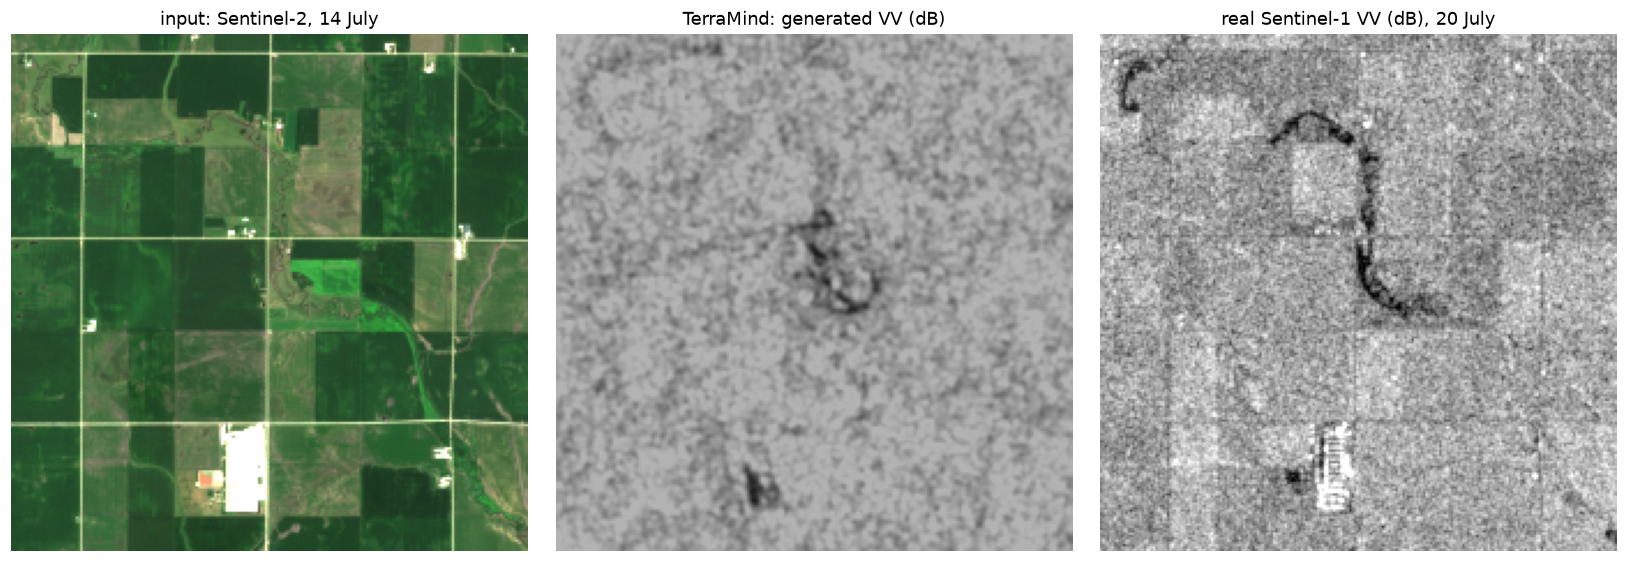

In [9]:
from terratorch.registry import FULL_MODEL_REGISTRY  # TerraTorch full models

gen = FULL_MODEL_REGISTRY.build("terratorch_terramind_v1_base_generate", modalities=["S2L2A"],
                                output_modalities=["S1GRD"], pretrained=True, standardize=False,
                                timesteps=10).to(DEVICE).eval()  # Sentinel-2 -> Sentinel-1 generator
win = dict(y=slice(400, 624), x=slice(600, 824))  # one 224 pixel (4.5 km) window
x2 = torch.as_tensor(fm.prepare("terramind-v1-base", s2.isel(**win)).values[None]).to(DEVICE)  # standardized S2
torch.manual_seed(SEED)  # the generation is stochastic
with torch.no_grad():  # inference only
    g = gen({"S2L2A": x2})["S1GRD"][0].float().cpu().numpy()  # generated, standardized
sp = fm.input_spec("terramind-v1-base")["S1GRD"]  # radar statistics
g_db = g * np.array(sp["std"])[:, None, None] + np.array(sp["mean"])[:, None, None]  # back to dB
real = s1.isel(**win).values  # the real Sentinel-1
del gen; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory

def corr(a, b, k=1):  # Pearson correlation after k x k averaging
    a = a.reshape(a.shape[0] // k, k, -1, k).mean((1, 3)); b = b.reshape(b.shape[0] // k, k, -1, k).mean((1, 3))  # block means
    m = np.isfinite(a) & np.isfinite(b)  # valid cells
    return np.corrcoef(a[m], b[m])[0, 1]  # correlation

print("mean dB  generated:", g_db.mean((1, 2)).round(2), "| real:", np.nanmean(real, (1, 2)).round(2))  # levels
print("correlation VV, pixels:", round(corr(g_db[0], real[0]), 3), "| 16 x 16 px blocks (320 m):", round(corr(g_db[0], real[0], 16), 3))  # agreement
fig, ax = plt.subplots(1, 3, figsize=(15, 5))  # input, generated, real
ax[0].imshow(np.clip(s2.isel(**win).sel(band=["red", "green", "blue"]).transpose("y", "x", "band").values / 0.15, 0, 1)); ax[0].set_title("input: Sentinel-2, 14 July")  # input
ax[1].imshow(g_db[0], cmap="gray", vmin=-20, vmax=-2); ax[1].set_title("TerraMind: generated VV (dB)")  # generated
ax[2].imshow(real[0], cmap="gray", vmin=-20, vmax=-2); ax[2].set_title("real Sentinel-1 VV (dB), 20 July")  # real
for a in ax:  # every panel
    a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # draw

The generated radar image has the right overall level (within about 0.6 dB of the real one in VV and
VH), and it places the river and the farmstead correctly, features the optical image shows clearly.
It does not reproduce the backscatter of individual fields: pixel correlation with the real image is
about 0.2, and about 0.5 after averaging to 320 m blocks. Generation is stochastic, so these numbers
change a little from run to run even with a fixed seed on the GPU. The generated image is a plausible radar
image of this kind of landscape, not a measurement of these fields six days later. Generated modalities
can fill gaps for visualization or as an extra input to TerraMind's own reasoning, but they are not a
substitute for an acquisition.

## An eight-band WorldView-2 image

WorldView-2 has bands that no Sentinel or Landsat sensor has, such as yellow (608 nm) and a second
near-infrared band (949 nm). GeoLattice has no band names for them, so DOFA receives the wavelengths
directly. The scene is a 1.6 m image of a Bangladesh landscape; a 448 pixel (720 m) window is
embedded in 224 pixel chips with patch features.

window without data: 29.7%


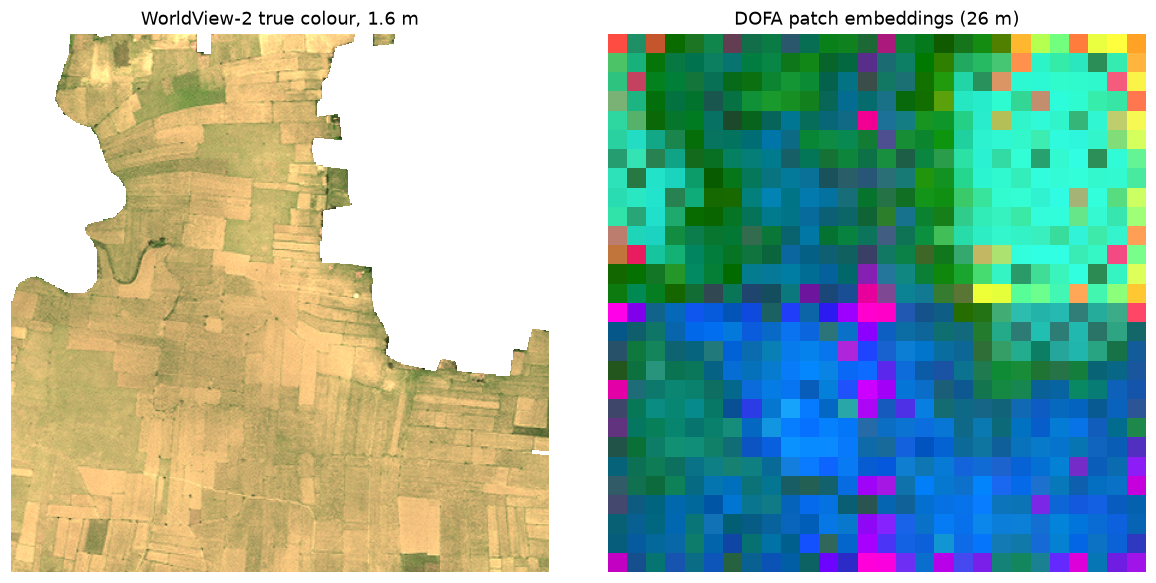

embedding map: {'embedding': 768, 'y': 28, 'x': 28}


In [10]:
WV2_NM = [427, 478, 546, 608, 659, 724, 833, 949]  # WorldView-2 band centres (nm): coastal to NIR2
import geopandas as gpd  # field polygons mark where the image has data
full = rioxarray.open_rasterio(WV2, masked=True)  # the whole scene (no-data around the edges)
cxf, cyf = gpd.read_file(WV2.parents[1] / "Labeled_data" / "aoi_trianing.shp").set_crs(full.rio.crs, allow_override=True).union_all().centroid.xy  # centre of the fields
ix, iy = int(np.abs(full.x - cxf[0]).argmin()), int(np.abs(full.y - cyf[0]).argmin())  # its pixel
wv = full.isel(y=slice(iy - 224, iy + 224), x=slice(ix - 224, ix + 224))  # 448 x 448 window over the fields
print(f"window without data: {float(wv.isnull().any('band').mean()):.1%}")  # check
wv = wv.assign_coords(band=[f"b{i}" for i in range(1, 9)])  # generic band names
dofa = fm.load_model("dofa-base", device=DEVICE, wavelengths=WV2_NM)  # DOFA told the wavelengths
wv_emb = dofa.embed_raster(wv, chip_size=224, dense=True)  # 16 px (26 m) patch features
del dofa; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
fig, ax = plt.subplots(1, 2, figsize=(11, 5.3))  # image and embeddings
v = wv.isel(band=[4, 2, 1]).transpose("y", "x", "band").values  # red, green, blue
ax[0].imshow(np.clip(v / np.nanpercentile(v, 98), 0, 1)); ax[0].set_title("WorldView-2 true colour, 1.6 m")  # image
ax[1].imshow(fm.embedding_rgb(wv_emb).transpose("y", "x", "band"), interpolation="nearest"); ax[1].set_title("DOFA patch embeddings (26 m)")  # embeddings
for a in ax:  # every panel
    a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # draw
print("embedding map:", dict(wv_emb.sizes))  # size

DOFA receives the eight WorldView-2 wavelengths, including the yellow and second near-infrared bands,
and produces patch features at 26 m (16 pixels of 1.6 m). The window is a mosaic of small fields, with
greener crops in the north-west and paler fallow or harvested fields in the south, and an area without
data in the top right. The embedding map follows that division: the greener northern fields and the
paler southern fields take different colours, and the empty area (filled with zeros after
normalization) is one uniform block, a reminder to mask no-data cells before using the embeddings.
Notebook 09_11_09 classifies these WorldView-2 fields with encoders built for very high resolution
imagery.

## Summary and exercises

### Summary

- Wavelength-conditioned (DOFA, Copernicus-FM), spectral-attention (Panopticon), paired-encoder
  (CROMA) and any-to-any (TerraMind) models read band sets and sensors a fixed-input model cannot.
- Reading a sensor is not the same as transferring between sensors: classifiers trained on
  Sentinel-2 embeddings lose accuracy on Landsat embeddings of the same fields, and the loss has to be
  measured against a band-value baseline.
- Copernicus-FM's location and date metadata change its embeddings; whether that helps depends on
  the task.
- A joint optical and radar embedding can be compared with optical-only and radar-only embeddings
  under simulated clouds.
- TerraMind generates a plausible radar image from optical input at the level of overall backscatter,
  but not as a substitute for a real Sentinel-1 acquisition.
- Unusual band sets such as WorldView-2's yellow and NIR2 bands are passed to DOFA as wavelengths.

### Exercises

1. Add Panopticon's Sentinel-1 embeddings to the transfer table: train on radar, predict on optical.
   What happens, and why?
2. Repeat the Copernicus-FM test with a wrong date (for example January). Does the probe notice?
3. Cloud the western (training) chips as well and retrain. Which CROMA embedding benefits most?
4. Generate S2L2A from S1GRD with TerraMind (swap `modalities` and `output_modalities`) and compare
   the generated NDVI with the real one.
5. Embed the WorldView-2 window with Panopticon (pass `wavelengths=WV2_NM`) and compare its map with DOFA's.

### References

- Fuller, A., Millard, K. and Green, J. R. (2023). CROMA: remote sensing representations with contrastive radar-optical masked autoencoders. NeurIPS.
- Jakubik, J. et al. (2025). TerraMind: large-scale generative multimodality for Earth observation. arXiv:2504.11171.
- Waldmann, L. et al. (2025). Panopticon. arXiv:2503.10845.
- Wang, Y. et al. (2025). Towards a unified Copernicus foundation model for Earth vision. arXiv:2503.11849.
- Xiong, Z. et al. (2024). DOFA. arXiv:2403.15356.